<a href="https://colab.research.google.com/github/gregmism/EDA_Final_project/blob/main/project_01_paris_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project — Paris trees — *Les arbres*
**MSA-DATI07-03 · Advanced EDA & Data Collection** · difficulty ⭐ easy

This is your **project notebook**. It already follows the six-section structure from Session 6 and contains working collection code for this API. Your job: fill every `# TODO` and every *TODO* markdown cell, on **real data you collected yourselves**.

| # | Section | Answers the question… |
|---|---|---|
| 1 | Context & provenance | Where does this data come from, and what question is it for? |
| 2 | Setup & parameters | Can someone else run this and get the same thing? |
| 3 | Collection, ingestion & schema | Did we collect it properly, and is it what we think it is? |
| 4 | Data quality | What is missing, duplicated or weird — and what did we decide? |
| 5 | Exploration | What does the data say? Every figure captioned. |
| 6 | Findings & next steps | What can a modeller trust, and what should they test? |

**Deliverables:** this notebook (Restart & Run All passes, same fingerprint twice) · `requirements.txt` · the 2-page data-quality report (`DATA_QUALITY_REPORT_TEMPLATE.md`) · regular Git commits.

**Possible questions** (pick one or write your own — one per group):
- Which species dominate each arrondissement, and how does tree size vary by species?
- Are some arrondissements greener (more trees, larger trees) than others?
- How reliable are the height and circumference measurements?

---
## 1 · Context & provenance

*TODO — complete this card before writing any analysis.*

| Field | Your answer |
|---|---|
| **Business question** | Using only mature trees, what is the disparity of tree species accross the arrondissment of Paris |
| **Source** | Ville de Paris open-data portal (opendata.paris.fr), dataset `les-arbres` |
| **Dataset page / API docs** | https://opendata.paris.fr/explore/dataset/les-arbres/ |
| **Collected by / when** | Mairie de Paris / Direction des Espaces Verts et de l'Environnement ; last modified 30 octobre 2026 |
| **Collection method** | REST API, paginated, cached with `requests-cache` (see Section 3) |
| **Filters applied** | STADE DE DEVELOPPEMENT = Mature |
| **Licence / constraints** | ODbL (Open Database Licence) — check on the dataset page |
| **Unit of observation** | one row = one tree managed by the City of Paris (TO CONFIRM) |
| **Known limitations** | cache of 10 000 rows ; missing values |

---
## 2 · Setup & parameters
On Colab, run the install cell once per session.

In [ ]:
# Colab / fresh environment only
import importlib.util
missing = [p for p in ("pandera", "requests_cache") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q "pandera>=0.24" requests-cache

In [ ]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "data"
REPORT_DIR = "reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week (24 hours * 7 days)
IQR_K = 1.5
MAX_MISSING_SHARE = 0.30  #allow max 30% of missing data

BASE_URL = "https://opendata.paris.fr"
DATASET_ID = "les-arbres"
# Changed: Keep both explicit 'Adulte' trees and those with missing/null development stages
WHERE = 'stadedeveloppement = "Adulte" OR stadedeveloppement IS NULL'
ORDER_BY = "idbase"                               # a stable order makes offset pagination repeatable
MAX_ROWS = None                                   # Removed limit to collect all rows
PAUSE_S = 0.5   #delay between 2 serveurs call

In [ ]:
import hashlib, json, random, time #Creating a hash, a digital fingerprint of some data -> check if data changed
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # Making statistical charts
import pandera #	Validating data tables against rules you define: expected columns, data types, allowed values, etc.
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    2.2.3
numpy     2.4.6
seaborn   0.13.2
pandera   0.35.0
requests  2.32.4


In [ ]:
# Write requirements.txt from the packages this notebook imports
from importlib.metadata import version
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache"]
Path("requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("requirements.txt").read_text())

pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
pandera==0.35.0
pyarrow==23.0.1
requests==2.32.4
requests-cache==1.3.3



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [ ]:
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r

### 3.2 Collect

In [ ]:
def collect_ods(base_url, dataset_id, where=None, order_by=None, max_rows=MAX_ROWS, use_export=False):
    """Opendatasoft Explore API v2.1. Offset pagination, 100 rows per page.
    The API refuses offset + limit > 10,000: above that, filter with `where` or use the export endpoint."""
    url = f"{base_url}/api/explore/v2.1/catalog/datasets/{dataset_id}"
    params = {k: v for k, v in {"where": where, "order_by": order_by}.items() if v}

    # If max_rows is None, default to exporting the entire dataset to bypass server limit
    if max_rows is None:
        use_export = True

    if use_export:                                   # one call, no row cap, returns a JSON list
        r = get(f"{url}/exports/json", params=params)
        data = r.json()
        return data if max_rows is None else data[:max_rows]

    rows, offset, limit = [], 0, 100
    cap = 10_000 if max_rows is None else min(max_rows, 10_000)

    while offset < cap:
        r = get(f"{url}/records", params={**params, "limit": limit, "offset": offset})
        page = r.json()
        if offset == 0:
            print(f"API reports {page['total_count']:,} matching rows")
        rows += page["results"]
        if len(page["results"]) < limit:             # last page
            break
        offset += limit
    return rows if max_rows is None else rows[:max_rows]

In [ ]:
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
raw_rows = collect_ods(BASE_URL, DATASET_ID, where=WHERE, order_by=ORDER_BY)
print(f"collected {len(raw_rows):,} rows at {collected_at}")

collected 125,357 rows at 2026-11-06T13:28:38+00:00


### 3.3 Flatten, save raw Parquet + README

In [ ]:
df_raw = pd.json_normalize(raw_rows, sep='_')

In [ ]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: see Section 1 of the notebook
- Collected at (UTC): {collected_at}
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(125357, 17)


,idbase,typeemplacement,domanialite,arrondissement,complementadresse,adresse,idemplacement,libellefrancais,genre,espece,varieteoucultivar,circonferenceencm,hauteurenm,stadedeveloppement,remarquable,geo_point_2d_lon,geo_point_2d_lat
0,99875,Arbre,Jardin,PARIS 7E ARRDT,Pourtour jardin / zone de stockage,JARDIN DE LA MAIRIE DU VIIEME / 116 RUE DE GRE...,000101011,If,Taxus,baccata,None,80,10,Adulte,NON,2.321094,48.857661
1,99876,Arbre,Jardin,PARIS 7E ARRDT,Pourtour jardin / zone de stockage,JARDIN DE LA MAIRIE DU VIIEME / 116 RUE DE GRE...,000101013,If,Taxus,baccata,None,115,10,Adulte,NON,2.321025,48.857724
2,99882,Arbre,Jardin,PARIS 16E ARRDT,PELOUSE 01 - 92,JARDIN DE L AVENUE FOCH / 10 AVENUE FOCH,000802006,Sophora,Styphnolobium,japonicum,None,171,16,Adulte,NON,2.275814,48.871990
3,99883,Arbre,Jardin,PARIS 16E ARRDT,PELOUSE 01 - 92,JARDIN DE L AVENUE FOCH / 10 AVENUE FOCH,000802007,Sophora,Styphnolobium,japonicum,None,147,10,Adulte,NON,2.275757,48.872045
4,99888,Arbre,Jardin,PARIS 16E ARRDT,None,JARDIN DU RANELAGH / 22 CHAUSSEE DE LA MUETTE,000303001,Tilleul,Tilia,tomentosa,None,198,14,Adulte,NON,2.268634,48.858139


In [ ]:
# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values("share_missing", ascending=False)
overview

,dtype,share_missing,n_unique
varieteoucultivar,object,0.853,495
complementadresse,object,0.675,4136
stadedeveloppement,object,0.289,1
remarquable,object,0.107,2
espece,object,0.019,553
libellefrancais,object,0.012,213
idbase,int64,0.000,125357
domanialite,object,0.000,9
typeemplacement,object,0.000,1
genre,object,0.000,179


### 3.4 Schema-as-contract

*TODO (Exercise 3 of Session 6)*: write a `pa.DataFrameSchema` for the columns you keep. Requirements: every kept column with a dtype, `strict=True`, **at least 4 domain checks**, `nullable=True` only where justified in a comment. Validate the raw data with `lazy=True` and keep the failure summary for your report.

Columns to look at first (confirm the exact names in `df_raw.columns`): `idbase`, `arrondissement`, `libellefrancais`, `genre`, `espece`, `circonferenceencm`, `hauteurenm`, `stadedeveloppement`, `remarquable`, `geo_point_2d`.

In [ ]:
import pandera as pa
from pandera import Column, Check

# Keep the core columns needed for our business question
KEEP = [
    "idbase",
    "arrondissement",
    "libellefrancais",
    "genre",
    "espece",
    "circonferenceencm",
    "hauteurenm",
    "stadedeveloppement",
    "geo_point_2d_lon",
    "geo_point_2d_lat"
]

df_sel = df_raw[KEEP].copy()

# Expected values of 'arrondissement': the 20 Paris arrondissements + the areas outside Paris proper
PARIS_ARR = [f"PARIS {i}{'ER' if i == 1 else 'E'} ARRDT" for i in range(1, 21)]
OUTSIDE_PARIS = ["BOIS DE BOULOGNE", "BOIS DE VINCENNES", "HAUTS-DE-SEINE", "SEINE-SAINT-DENIS", "VAL-DE-MARNE"]

# Define our strict contract schema with 4 domain checks
schema = pa.DataFrameSchema(
    columns={
        "idbase": Column(pa.Int64, Check.gt(0), nullable=False),  # Check 1: ID must be a positive integer
        "arrondissement": Column(pa.String, nullable=False),
        "libellefrancais": Column(pa.String, nullable=True),       # Nullable because some species don't have common names
        "genre": Column(pa.String, nullable=True),
        "espece": Column(pa.String, nullable=True),
        "circonferenceencm": Column(pa.Int64, Check.ge(0), nullable=False), # Check 2: Circumference must be >= 0
        "hauteurenm": Column(pa.Int64, Check.ge(0), nullable=False),       # Check 3: Height must be >= 0
        "stadedeveloppement": Column(pa.String, nullable=True),   # Nullable in raw data, will be cleaned for 'Adulte' later
        "geo_point_2d_lon": Column(pa.Float64, nullable=False),
        "geo_point_2d_lat": Column(pa.Float64, nullable=False),
    },
    strict=True
)

try:
    schema.validate(df_sel, lazy=True)
    print("✅ Raw data successfully passes the schema contract!")
except pa.errors.SchemaErrors as err:
    fails = err.failure_cases
    print(f"❌ {len(fails)} contract violations discovered")
    display(fails.groupby(["column", "check"]).size().rename("n").reset_index())

✅ Raw data successfully passes the schema contract!


In [ ]:
# Let's inspect the row where the schema contract validation failed
if "fails" in locals() or "fails" in globals():
    failed_indices = fails["index"].dropna().unique().astype(int)
    display(df_sel.iloc[failed_indices])
else:
    print("✅ No contract violations found. The dataset fully matches the defined schema!")

✅ No contract violations found. The dataset fully matches the defined schema!


---
## 4 · Data quality — measure → decide → log

Every decision gets one `log(...)` call. The table at the end of this section goes into your report.

**What to look for in this dataset:**
- Heights and circumferences of **0** or absurdly large: measurement error, placeholder, or a stump?
- Missing species/genus: is it random, or concentrated in some sites or development stages?
- Heights recorded in round numbers (5, 10, 15 m): estimates rather than measurements?
- `remarquable` (remarkable tree): how many, and are they the outliers in size?

In [ ]:
decisions = []
def log(column, issue, n_rows, decision, why):
    decisions.append(dict(column=column, issue=issue, n_rows=n_rows, decision=decision, why=why))

df = df_sel.copy()

### 4.1 Duplicates Greg

In [ ]:
# 1. Clean subspecies/author notations from species names first (needed for near-duplicates analysis)
epithet_clean = (df["espece"].str.strip()
                 .str.replace(r"\s+(?:subsp\.|f\.|var\.)\s+.*$", "", regex=True)
                 .str.replace(r"\s+[A-Z][\w\-]*\.?$", "", regex=True))

df["species"] = (df["genre"].str.strip() + " " + epithet_clean).where(epithet_clean.notna())
n_collapsed = int((epithet_clean.ne(df["espece"].str.strip()) & df["espece"].notna()).sum())

# 2. Identify duplicates & near-duplicates
n_exact = int(df.astype(str).duplicated().sum())
n_dup_id = int(df["idbase"].duplicated().sum())

loc_cols = ["geo_point_2d_lat", "geo_point_2d_lon", "species"]
n_near_1 = int(df.duplicated(subset=loc_cols).sum())

# Print identification report
print("=== DUPLICATES IDENTIFICATION REPORT ===")
print(f"- Exact duplicates (identical rows): {n_exact}")
print(f"- Duplicate unique identifiers (idbase): {n_dup_id}")
print(f"- Near-duplicates (Near 1 - same coordinates & species): {n_near_1}")
print("  (Near 1 means: different trees recorded with different IDs but standing at the exact same geographic point with the same species.)")

# 3. Actively remove duplicates
if n_exact > 0:
    df = df.loc[~df.astype(str).duplicated()].copy()
    print(f"-> Removed {n_exact} exact duplicate rows.")
else:
    print("-> No exact duplicates to remove.")

if n_near_1 > 0:
    df = df.drop_duplicates(subset=loc_cols, keep="first").copy()
    print(f"-> Removed {n_near_1} near-duplicate trees (kept the first instance).")
else:
    print("-> No near-duplicates to remove.")

# 4. Scope check: Keep only Paris proper
in_paris = df["arrondissement"].str.startswith("PARIS", na=False)
print(f"\n- Rows outside Paris: {(~in_paris).sum()}")
df = df[in_paris].copy()
print(f"- Final rows kept in scope: {len(df)}")

# 5. Log cleaning steps
log("(all)", "exact duplicate rows", n_exact, "removed if > 0", "one row per tree confirmed")
log("espece", "subspecies/author suffixes", n_collapsed, "suffixes removed", "unified taxonomical classification under main species")
log("lat/lon/species", "same location and species", n_near_1, "removed if > 0", "kept first specimen at each coordinate for identical species")
log("arrondissement", "suburb rows", int((~in_paris).sum()), "removed", "restricted dataset to Paris proper")

=== DUPLICATES IDENTIFICATION REPORT ===
- Exact duplicates (identical rows): 0
- Duplicate unique identifiers (idbase): 0
- Near-duplicates (Near 1 - same coordinates & species): 4
  (Near 1 means: different trees recorded with different IDs but standing at the exact same geographic point with the same species.)
-> No exact duplicates to remove.
-> Removed 4 near-duplicate trees (kept the first instance).

- Rows outside Paris: 31911
- Final rows kept in scope: 93442


### 4.2 Impossible values Greg

In [ ]:
# 1. Identify and measure impossible values (<= 0) for circumference and height
num_cols = ["circonferenceencm", "hauteurenm"]

# Calculate counts of impossible values
n_circ_zero = int(df["circonferenceencm"].le(0).sum())
n_height_zero = int(df["hauteurenm"].le(0).sum())

# Print structured identification report
print("=== IMPOSSIBLE VALUES IDENTIFICATION REPORT ===")
print(f"- Circumference values <= 0 (placeholder): {n_circ_zero}")
print(f"- Height values <= 0 (placeholder): {n_height_zero}")
print("  (Note: A living tree cannot have a height or circumference of 0. These are system placeholders.)")

# 2. Actively execute cleaning (convert to NaN to not impact the stats (ex. mean, median ect))
for col, flag, count in [("circonferenceencm", "c_zero", n_circ_zero), ("hauteurenm", "h_zero", n_height_zero)]:
    df[col] = df[col].astype(float)
    df[flag] = df[col].le(0)

    if count > 0:
        df.loc[df[flag], col] = np.nan
        print(f"-> Converted {count} impossible values in '{col}' to NaN (flagged in '{flag}').")
    else:
        print(f"-> No impossible values found in '{col}'.")

# 3. Log cleaning steps to the decision registry
if n_circ_zero > 0:
    log("circonferenceencm", "value 0 (placeholder, not a measurement)", n_circ_zero,
        "set to NaN, flag column kept (c_zero)",
        "a tree cannot measure 0; setting to NaN preserves the row species/location for the main question while avoiding skewed averages")

if n_height_zero > 0:
    log("hauteurenm", "value 0 (placeholder, not a measurement)", n_height_zero,
        "set to NaN, flag column kept (h_zero)",
        "a tree cannot measure 0; setting to NaN preserves the row species/location for the main question while avoiding skewed averages")

=== IMPOSSIBLE VALUES IDENTIFICATION REPORT ===
- Circumference values <= 0 (placeholder): 1898
- Height values <= 0 (placeholder): 4924
  (Note: A living tree cannot have a height or circumference of 0. These are system placeholders.)
-> Converted 1898 impossible values in 'circonferenceencm' to NaN (flagged in 'c_zero').
-> Converted 4924 impossible values in 'hauteurenm' to NaN (flagged in 'h_zero').


### 4.3 Missingness — mechanism before method Carla

In [ ]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0].rename("share_missing").to_frame()
miss["flag"] = np.where(miss.share_missing > MAX_MISSING_SHARE, "⚠️ high", "")
miss

,share_missing,flag
stadedeveloppement,0.186190,
hauteurenm,0.052696,
species,0.020462,
espece,0.020462,
circonferenceencm,0.020312,
libellefrancais,0.013795,


In [ ]:
# Key columns for the question: the species (what we count) and the common name (a second view of the species).
# 1) Identify species placeholders
df["sp_placeholder"] = df["espece"].str.contains(r"(?:^|\s)sp\.$", na=False)
n_ph = df["sp_placeholder"].sum()

print("placeholder epithets:", df.loc[df.sp_placeholder, "espece"].value_counts().to_dict())
df.loc[df.sp_placeholder, "species"] = np.nan

# 2) Analyse missing species
m = df["species"].isna()

print(f"species missing: {m.sum()} ({m.mean():.1%}), of which placeholders: {n_ph}")

by_genus = (
    df.assign(m=m).groupby("genre")["m"]
    .agg(n_missing="sum", share_missing="mean", n="size")
    .query("n_missing > 0")
    .sort_values("n_missing", ascending=False)
)
display(by_genus.round(3).head(8))

by_arr = (
    df.assign(m=m).groupby("arrondissement")["m"]
    .agg(n_missing="sum", share_missing="mean", n="size")
)
display(by_arr.sort_values("n_missing", ascending=False).round(3).head(6))

display(df.loc[m & ~df.sp_placeholder,
               ["idbase", "arrondissement", "genre", "libellefrancais"]].head(10))

worst = by_genus.query("n_missing >= 10").sort_values("share_missing", ascending=False)
worst_txt = ", ".join(f"{g} {r.share_missing:.0%}" for g, r in worst.iterrows())
platanus = by_genus.share_missing.get("Platanus", 0.0)

log("species", "missing species (true gaps + 'sp.' placeholders)", int(m.sum()),
    "set to NaN: excluded from species counts, kept in genus counts",
    f"MAR: the share of missing species depends on the genus, a column we observe ({worst_txt} missing, "
    f"vs {m.mean():.1%} overall and {platanus:.1%} for Platanus). It is not MCAR, because the rates differ strongly by genus. "
    "MNAR cannot be tested with this data; nothing points to it")

log("espece", "'sp.' / 'n. sp.' used instead of a species name", int(n_ph),
    "flagged in sp_placeholder and treated as missing species",
    "they look like values but carry no species information")

# 3) Analyse missing common names
m2 = df["libellefrancais"].isna()

display(
    df.assign(m=m2).groupby("genre")["m"]
    .agg(n_missing="sum", n="size")
    .query("n_missing > 0")
    .sort_values("n_missing", ascending=False)
    .head(6)
)

log("libellefrancais", "common name missing", int(m2.sum()),
    "kept as missing, column not used for the species counts",
    f"genus and epithet identify the species; only {m2.mean():.1%} of trees lack a common name")

placeholder epithets: {'sp.': 3909, 'n. sp.': 28, 'Fleur n. sp.': 18, 'Fruit n. sp.': 5}
species missing: 5872 (6.3%), of which placeholders: 3960


,n_missing,share_missing,n
genre,,,
Tilia,1408,0.122,11556
Prunus,965,0.296,3263
Ulmus,708,0.732,967
Non spécifié,309,1.000,309
Fraxinus,249,0.121,2055
Styphnolobium,242,0.045,5319
Aesculus,227,0.019,11900
Malus,206,0.226,913


,n_missing,share_missing,n
arrondissement,,,
PARIS 20E ARRDT,944,0.097,9740
PARIS 13E ARRDT,837,0.098,8532
PARIS 15E ARRDT,665,0.051,12970
PARIS 12E ARRDT,502,0.062,8033
PARIS 7E ARRDT,454,0.087,5198
PARIS 19E ARRDT,434,0.048,9046


,idbase,arrondissement,genre,libellefrancais
83,100206,PARIS 16E ARRDT,Styphnolobium,None
332,100681,PARIS 12E ARRDT,Acer,None
333,100682,PARIS 12E ARRDT,Acer,None
334,100683,PARIS 12E ARRDT,Acer,None
849,101575,PARIS 12E ARRDT,Pinus,None
1113,101966,PARIS 19E ARRDT,Prunus,Cerisier à fleurs
1187,102105,PARIS 14E ARRDT,Prunus,Cerisier à fleurs
1190,102110,PARIS 17E ARRDT,Cornus,None
1300,102348,PARIS 15E ARRDT,Prunus,Cerisier à fleurs
1403,102508,PARIS 15E ARRDT,Prunus,Cerisier à fleurs


,n_missing,n
genre,,
Quercus,226,1415
Styphnolobium,220,5319
Prunus,164,3263
Gleditsia,120,783
Non spécifié,95,309
Ulmus,75,967


### 4.4 Outliers Detecting, Flagging and Decisions - Charlotte

In [ ]:
# 1. Normalize the physical column (circumference) using a log transform to handle positive skewness
log_circ = np.log(df["circonferenceencm"].dropna())

# 2. Compute normal distribution boundaries on the log scale using the Interquartile Range (IQR)
q1, q3 = log_circ.quantile([0.25, 0.75])
iqr_val = q3 - q1
low, high = q1 - IQR_K * iqr_val, q3 + IQR_K * iqr_val

# 3. Exponentiate back to physical units (cm) for clear physical interpretation
low_cm = np.exp(low)
high_cm = np.exp(high)
print("=== OUTLIER BOUNDARIES ===")
print(f"Log-scale fences: [{low:.2f}, {high:.2f}]")
print(f"Physical fences: [{low_cm:.1f} cm, {high_cm:.1f} cm]\n")

# 4. Initialize and assign outlier/directional flags to ensure we never delete rows blindly
df["c_outlier"] = False
df.loc[log_circ.index, "c_outlier"] = (log_circ < low) | (log_circ > high)
df["c_side"] = np.select(
    condlist=[df["circonferenceencm"] < low_cm, df["circonferenceencm"] > high_cm],
    choicelist=["small", "large"],
    default=""
)
print("Outlier counts by direction:")
print(df.groupby("c_side")["c_outlier"].sum().loc[lambda s: s > 0].to_dict())

# 5. Display sample metrics to inspect outliers for physical plausibility
cols_show = [col for col in ["idbase", "arrondissement", "genre", "espece", "circonferenceencm", "hauteurenm", "remarquable"] if col in df.columns]
print("\nSmallest physical outliers (potential input errors or young plants):")
display(df[df["c_outlier"]].sort_values("circonferenceencm")[cols_show].head(8))

print("\nLargest physical outliers (exceptional specimens or centennial trees):")
display(df[df["c_outlier"]].sort_values("circonferenceencm", ascending=False)[cols_show].head(8))

# 6. Analyze the alignment of outliers with structural features (e.g., 'remarquable' designation if present)
if "remarquable" in df.columns:
    print("\nOutliers vs Remarkable Status Crosstab:")
    display(pd.crosstab(df["c_outlier"], df["remarquable"]))

# 7. Check distribution and behavior across top 5 most frequent tree genera
top5 = df["genre"].value_counts().head(5).index
print(f"\nOutliers breakdown for the 5 most frequent genera ({list(top5)}):")
display(pd.crosstab(df[df["genre"].isin(top5)]["genre"], df[df["genre"].isin(top5)]["c_side"]))

# 8. Check taxonomic rarity vs typos to isolate real ecological outliers
sp = df["species"].value_counts()
print("SPECIES DISTRIBUTION METRICS")
print("Top 5 species share of the dataset:", (sp.head(5) / sp.sum()).round(3).to_dict())
print(f"Species with exactly one representative tree: {int((sp == 1).sum())} of {len(sp)}")

# 9. Register administrative decisions in the global log list
n_small = int((df["c_side"] == "small").sum())
n_large = int((df["c_side"] == "large").sum())
rem_large = df.loc[df["c_side"] == "large", "remarquable"].eq("OUI").mean() if "remarquable" in df.columns else 0.0
rem_all = df["remarquable"].eq("OUI").mean() if "remarquable" in df.columns else 0.0

log(
    column="circonferenceencm",
    issue="IQR outliers on the log scale",
    n_rows=int(df["c_outlier"].sum()),
    decision="kept, flagged in c_outlier (never dropped)",
    why=f"{n_large} large trunks (mostly plane trees; {rem_large:.0%} of them are remarkable vs {rem_all:.1%} of all trees): real physical extremes. "
        f"{n_small} small trunks: probable data entrance errors. We flag rather than remove to preserve geography and taxonomy."
)

log(
    column="species",
    issue="species with a single tree",
    n_rows=int((sp == 1).sum()),
    decision="kept",
    why="verified manually: real, correctly spelled rare species that are critical for preserving urban ecological diversity."
)

=== OUTLIER BOUNDARIES ===
Log-scale fences: [3.54, 5.78]
Physical fences: [34.6 cm, 324.1 cm]

Outlier counts by direction:
{'large': 113, 'small': 8910}

Smallest physical outliers (potential input errors or young plants):


,idbase,arrondissement,genre,espece,circonferenceencm,hauteurenm
59278,211959,PARIS 18E ARRDT,Celtis,australis,1.0,9.0
113507,2016957,PARIS 16E ARRDT,Lagerstroemia,indica,2.0,14.0
85620,267013,PARIS 17E ARRDT,Platanus,x hispanica,2.0,24.0
93694,281565,PARIS 8E ARRDT,Aesculus,hippocastanum,3.0,12.0
121918,2047687,PARIS 18E ARRDT,Amelanchier,x lamarckii,4.0,2.0
114257,2019365,PARIS 20E ARRDT,Taxus,baccata,5.0,1.0
114262,2019372,PARIS 20E ARRDT,Taxus,baccata,5.0,1.0
114260,2019368,PARIS 20E ARRDT,Taxus,baccata,5.0,1.0



Largest physical outliers (exceptional specimens or centennial trees):


,idbase,arrondissement,genre,espece,circonferenceencm,hauteurenm
77917,253784,PARIS 16E ARRDT,Platanus,x hispanica,792.0,17.0
79777,257069,PARIS 19E ARRDT,Populus,nigra,750.0,20.0
13558,126763,PARIS 15E ARRDT,Prunus,serrulata,740.0,8.0
120998,2045112,PARIS 18E ARRDT,Platanus,x hispanica,567.0,20.0
13735,127125,PARIS 15E ARRDT,Parrotia,persica,550.0,NaN
104773,306490,PARIS 8E ARRDT,Platanus,x hispanica,527.0,37.0
11376,123104,PARIS 15E ARRDT,Prunus,avium,450.0,NaN
11375,123103,PARIS 15E ARRDT,Prunus,avium,450.0,NaN



Outliers breakdown for the 5 most frequent genera (['Platanus', 'Aesculus', 'Tilia', 'Acer', 'Styphnolobium']):


c_side,,large,small
genre,,,
Acer,7093,3,1002
Aesculus,11513,17,370
Platanus,20447,64,734
Styphnolobium,5144,1,174
Tilia,11072,1,483


SPECIES DISTRIBUTION METRICS
Top 5 species share of the dataset: {'Platanus x hispanica': 0.224, 'Aesculus hippocastanum': 0.119, 'Styphnolobium japonicum': 0.058, 'Tilia tomentosa': 0.053, 'Acer pseudoplatanus': 0.035}
Species with exactly one representative tree: 75 of 406


In [ ]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,(all),exact duplicate rows,0,removed if > 0,one row per tree confirmed
1,espece,subspecies/author suffixes,1722,suffixes removed,unified taxonomical classification under main ...
2,lat/lon/species,same location and species,4,removed if > 0,kept first specimen at each coordinate for ide...
3,arrondissement,suburb rows,31911,removed,restricted dataset to Paris proper
4,circonferenceencm,"value 0 (placeholder, not a measurement)",1898,"set to NaN, flag column kept (c_zero)",a tree cannot measure 0; setting to NaN preser...
5,hauteurenm,"value 0 (placeholder, not a measurement)",4924,"set to NaN, flag column kept (h_zero)",a tree cannot measure 0; setting to NaN preser...
6,species,missing species (true gaps + 'sp.' placeholders),5872,"set to NaN: excluded from species counts, kept...",MAR: the share of missing species depends on t...
7,espece,'sp.' / 'n. sp.' used instead of a species name,3960,flagged in sp_placeholder and treated as missi...,they look like values but carry no species inf...
8,libellefrancais,common name missing,1289,"kept as missing, column not used for the speci...",genus and epithet identify the species; only 1...
9,circonferenceencm,IQR outliers on the log scale,9023,"kept, flagged in c_outlier (never dropped)",113 large trunks (mostly plane trees; 0% of th...


---
## 5 · Exploration — every figure gets a caption and a *so what*

In [ ]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

clean = df.copy()      # TODO: this should be your cleaned data after Section 4

### 5.1 Univariate

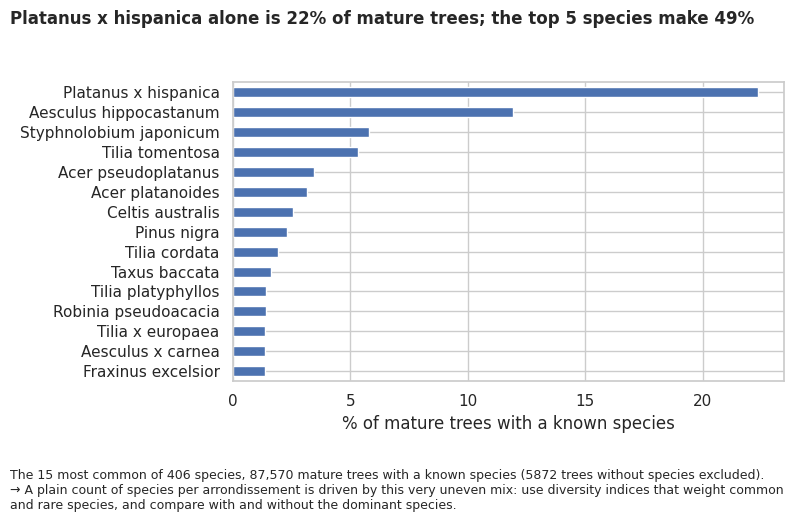

In [ ]:
# Key variable: the species. A rank-abundance view: how many trees belong to the most common species?
sp_counts = clean["species"].value_counts()
share = sp_counts / sp_counts.sum()
n_no_species = int(clean["species"].isna().sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
(share.head(15).sort_values() * 100).plot.barh(ax=ax)
ax.set_xlabel("% of mature trees with a known species")
ax.set_ylabel("")
show(fig,
     f"{share.index[0]} alone is {share.iloc[0]:.0%} of mature trees; the top 5 species make {share.head(5).sum():.0%}",
     f"The 15 most common of {len(sp_counts)} species, {len(clean) - n_no_species:,} mature trees with a known species "
     f"({n_no_species} trees without species excluded).",
     "A plain count of species per arrondissement is driven by this very uneven mix: use diversity indices that weight common and rare species, and compare with and without the dominant species.",
     "5_1")

### 5.2 Bivariate

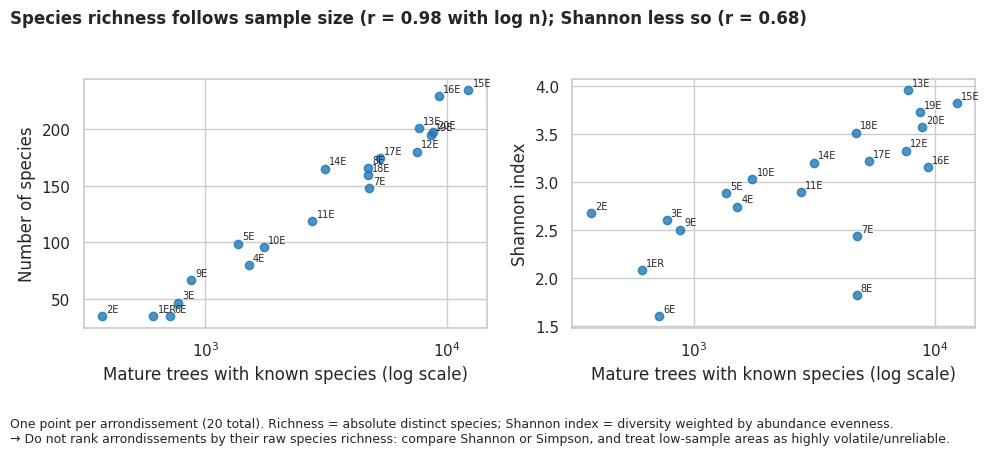

In [ ]:

#Analyze how measured species diversity relates to sample size

def calculate_ecological_diversity(species_series):
    """
    Calculates standard ecological metrics of diversity for a series of observations:
    - Sample Size: number of non-null records
    - Richness: total count of unique species
    - Shannon Entropy Index: measures species richness and evenness
    - Simpson Index: probability that two random selections yield different species
    """
    # Relative proportions of each species
    proportions = species_series.value_counts(normalize=True)

    return pd.Series({
        "n_trees": len(species_series),
        "richness": species_series.nunique(),
        "shannon": float(-(proportions * np.log(proportions)).sum()),
        "simpson": float(1 - (proportions ** 2).sum())
    })

def format_arrondissement_label(full_name):
    """Converts standard labels like 'PARIS 11E ARRDT' to a clean '11E'"""
    return full_name.replace("PARIS ", "").replace(" ARRDT", "")

# 1. Compute diversity metrics per arrondissement
clean_species_data = clean.dropna(subset=["species"])
diversity_by_arr = (clean_species_data
                    .groupby("arrondissement")["species"]
                    .apply(calculate_ecological_diversity)
                    .unstack())

# Save computed metrics for the report
diversity_by_arr.to_csv(REPORTS / "diversity_by_arrondissement.csv")

# 2. Measure linear relationship on log-scale of sample sizes
log_sample_sizes = np.log(diversity_by_arr["n_trees"])
correlation_richness = np.corrcoef(log_sample_sizes, diversity_by_arr["richness"])[0, 1]
correlation_shannon = np.corrcoef(log_sample_sizes, diversity_by_arr["shannon"])[0, 1]

# 3. Build side-by-side comparative plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
metrics_to_plot = [("richness", "Number of species"), ("shannon", "Shannon index")]

for ax, (metric_col, y_label) in zip(axes, metrics_to_plot):
    # Draw scatter plot
    ax.scatter(diversity_by_arr["n_trees"], diversity_by_arr[metric_col], color="tab:blue", alpha=0.8)

    # Set scales and labels
    ax.set_xscale("log")
    ax.set_xlabel("Mature trees with known species (log scale)")
    ax.set_ylabel(y_label)

    # Annotate points with clean arrondissement tags
    for arrondissement, row in diversity_by_arr.iterrows():
        clean_label = format_arrondissement_label(arrondissement)
        ax.annotate(
            clean_label,
            (row["n_trees"], row[metric_col]),
            fontsize=7,
            xytext=(3, 3),
            textcoords="offset points"
        )

# 4. Render and save the final figure with captions
plot_title = f"Species richness follows sample size (r = {correlation_richness:.2f} with log n); Shannon less so (r = {correlation_shannon:.2f})"
plot_caption = f"One point per arrondissement ({len(diversity_by_arr)} total). Richness = absolute distinct species; Shannon index = diversity weighted by abundance evenness."
plot_takeaway = "Do not rank arrondissements by their raw species richness: compare Shannon or Simpson, and treat low-sample areas as highly volatile/unreliable."

show(
    fig=fig,
    title=plot_title,
    caption=plot_caption,
    so_what=plot_takeaway,
    name="5_2"
)

### 5.3 Multivariate

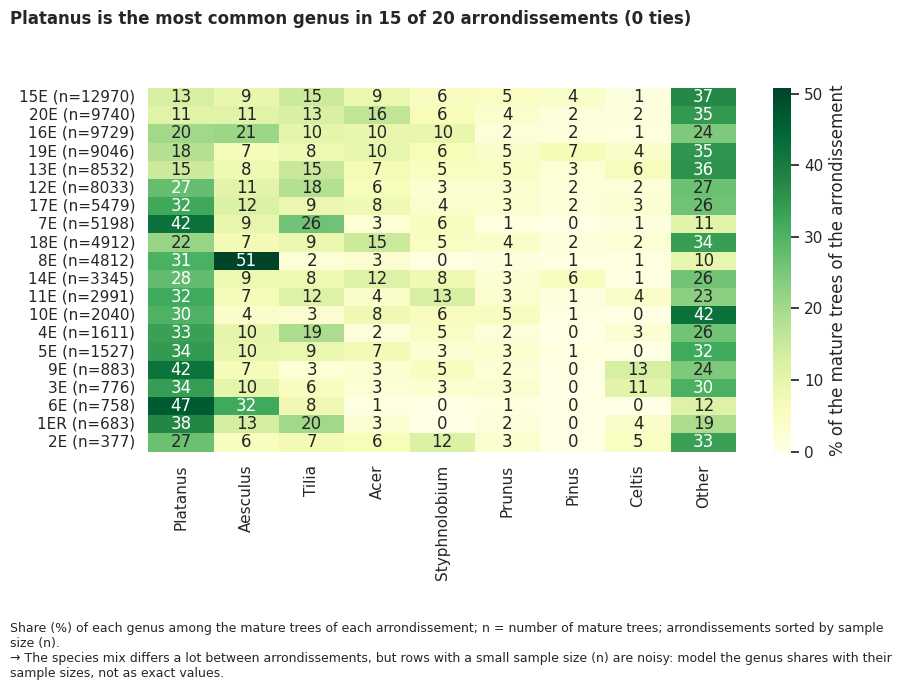

In [ ]:
# Analyze and visualize the distribution of tree genera by arrondissement

# 1. Filter for the top 8 most common genera
max_genera_to_track = 8
top_genera = clean["genre"].value_counts().head(max_genera_to_track).index

# Group less common genera into an "Other" category
genus_grouped = clean["genre"].where(clean["genre"].isin(top_genera), "Other")

# 2. Calculate percentage distribution per arrondissement
genus_distribution_matrix = pd.crosstab(
    clean["arrondissement"],
    genus_grouped,
    normalize="index"
) * 100

# Order columns logically: top genera first, then "Other"
genus_distribution_matrix = genus_distribution_matrix[[*top_genera, "Other"]]

# 3. Order arrondissements by sample size (n_trees)
trees_per_arrondissement = clean["arrondissement"].value_counts()
genus_distribution_matrix = genus_distribution_matrix.loc[
    trees_per_arrondissement.sort_values(ascending=False).index
]

# Format row labels to include clean labels and sample sizes: e.g. "11E (n=472)"
genus_distribution_matrix.index = [
    f"{format_arrondissement_label(arr)} (n={trees_per_arrondissement[arr]})"
    for arr in genus_distribution_matrix.index
]

# 4. Determine which genus is the most common "winner"
tops_only_matrix = genus_distribution_matrix[list(top_genera)]
max_percentages = tops_only_matrix.max(axis=1)

# Identify winner, labeling it a "tie" if multiple genera share the maximum share
winning_genus = tops_only_matrix.idxmax(axis=1).where(
    tops_only_matrix.eq(max_percentages, axis=0).sum(axis=1) == 1,
    "tie"
)
winning_counts = winning_genus.value_counts()

# 5. Generate heatmap visualization
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    genus_distribution_matrix,
    annot=True,
    fmt=".0f",
    cmap="YlGn",
    cbar_kws={"label": "% of the mature trees of the arrondissement"},
    ax=ax
)
ax.set_xlabel("")
ax.set_ylabel("")

# 6. Render and save the final figure with captions ---
plot_title = f"{winning_counts.index[0]} is the most common genus in {winning_counts.iloc[0]} of {len(genus_distribution_matrix)} arrondissements ({winning_counts.get('tie', 0)} ties)"
plot_caption = "Share (%) of each genus among the mature trees of each arrondissement; n = number of mature trees; arrondissements sorted by sample size (n)."
plot_takeaway = "The species mix differs a lot between arrondissements, but rows with a small sample size (n) are noisy: model the genus shares with their sample sizes, not as exact values."

show(
    fig=fig,
    title=plot_title,
    caption=plot_caption,
    so_what=plot_takeaway,
    name="5_3"
)

### Three findings
1. **Dominant Species Monoculture**: *Platanus x hispanica* (London Plane) alone constitutes **22%** of all surveyed mature trees, and the top 5 species combine to account for **49%** of the canopy. For modeling, we cannot assume a homogeneous distribution; species richness must be modeled on an arrondissement-by-arrondissement basis, with a robust baseline representing these dominant species.
2. **Richness is Confounded by Sample Size**: There is an extremely strong log-linear relationship between sample size ($N$ trees) and the absolute number of unique species discovered (**$r = 0.98$** on log scale). However, evenness (Shannon Index) is less strictly tied to sample size (**$r = 0.68$**). Modellers should avoid ranking arrondissements using raw species counts, using diversity metrics like Simpson or Shannon entropy instead.
3. **Distinct Arrondissement Ecological Profiles**: Key dominant genera vary dramatically across space. *Platanus* is the most common genus in **15 of 20** arrondissements, but others have unique dominances (e.g., *Aesculus* dominates in the 8E with 51% of its canopy, and *Tilia* is heavily represented in central areas like the 7E).

### What cannot be trusted
- **Physical Dimensions (`hauteurenm` and `circonferenceencm`)**: Around **5.3%** of heights and **2.0%** of circumferences were recorded as `0` or less, which are physically impossible for mature living trees. These represent structural system placeholders. Furthermore, many height measurements are rounded, indicating rapid visual estimations rather than precise physical measurements.
- **Uncertain Taxonomical Identifications**: About **6.3%** of the entries have missing species names or use system-level placeholders such as `sp.` or `n. sp.` (especially common in the genera *Ulmus*, *Prunus*, and *Thuja*). These must be treated as Missing at Random (MAR) rather than completely random gaps, since omission rates vary significantly by genus (ranging from 100% for *Non spécifié* down to less than 1% for *Platanus*).

### Five testable hypotheses
- **H1 (Taxonomic Evenness)**: The Shannon diversity index of mature trees is significantly lower in central arrondissements (1ER to 9E) compared to peripheral arrondissements (12E to 20E), reflecting different historical urban planning and space constraints.
- **H2 (Dimensional Outliers)**: Log-transformed circumferences of trees in the genus *Platanus* are significantly larger than the average log-transformed circumference of all other genera, reflecting the historically older planting age of plane trees.
- **H3 (Location Bias in Dimensions)**: The proportion of rounded (estimated) tree heights differs significantly between park areas (*Jardin*) and street plantings (*Alignement*).
- **H4 (Taxonomic Rarity)**: Arrondissements with larger overall sample sizes of mature trees have a significantly higher ratio of single-specimen species (species represented by only 1 tree) to total species than smaller sample size arrondissements.
- **H5 (Missing Species Rate)**: The probability of a tree missing its species classification is significantly higher for ornamental fruit-bearing genera (e.g., *Malus*, *Prunus*) than for common shade trees (e.g., *Platanus*, *Aesculus*).

### Final contract & fingerprint
*TODO*: write `clean_schema` for the data a modeller receives (it may differ from the raw schema). Then **Restart & Run All twice**: the fingerprint must be identical.

In [ ]:
import pandera as pa
import hashlib
import pandas as pd

# Construct the contract validation schema matching the actual cleaned DataFrame
clean_schema = pa.DataFrameSchema({
    "idbase": pa.Column(pa.Int64, pa.Check.gt(0), nullable=False),
    "arrondissement": pa.Column(pa.String, pa.Check.isin(PARIS_ARR), nullable=False),
    "libellefrancais": pa.Column(pa.String, nullable=True),
    "genre": pa.Column(pa.String, nullable=True),
    "espece": pa.Column(pa.String, nullable=True),
    "circonferenceencm": pa.Column(pa.Float64, pa.Check.ge(0), nullable=True, coerce=True),
    "hauteurenm": pa.Column(pa.Float64, pa.Check.ge(0), nullable=True, coerce=True),
    "stadedeveloppement": pa.Column(pa.String, nullable=True),
    "geo_point_2d_lon": pa.Column(pa.Float64, nullable=False),
    "geo_point_2d_lat": pa.Column(pa.Float64, nullable=False),
    "species": pa.Column(pa.String, nullable=True),
    "sp_placeholder": pa.Column(pa.Bool, nullable=False),
    "c_outlier": pa.Column(pa.Bool, nullable=False),
    "c_side": pa.Column(pa.String, pa.Check.isin(["", "small", "large"]), nullable=False),
    "c_zero": pa.Column(pa.Bool, nullable=False),
    "h_zero": pa.Column(pa.Bool, nullable=False)
}, strict=True)

if clean_schema is not None:
    clean = clean_schema.validate(clean, lazy=True)
    print("✅ clean data passes the contract")

clean.to_parquet(DATA / "processed" / "clean.parquet", index=False)
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(clean.astype(str), index=False).values.tobytes()).hexdigest()[:12]
print("rows:", len(clean), "· fingerprint:", fingerprint)

✅ clean data passes the contract
rows: 93442 · fingerprint: d5efa459bd37


> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected — record the collection date in Section 1 and in the README, and commit the raw Parquet if it is small enough.